MULTIFRACTAL OPTIONS PRICING MODEL — PAPER 2 VERIFICATION

  ✓ AAPL: 4092 days
  ✓ MSFT: 4092 days
  ✓ AMZN: 4092 days
  ✓ TSLA: 3970 days
  ✓ NVDA: 4092 days
  ✓ JPM: 4092 days
  ✓ GS: 4092 days
  ✓ MS: 4092 days
  ✓ BAC: 4092 days
  ✓ JNJ: 4092 days
  ✓ KO: 4092 days
  ✓ PEP: 4092 days
  ✓ XOM: 4092 days
  ✓ CVX: 4092 days
  ✓ BTC-USD: 4224 days
  ✓ ETH-USD: 3075 days

Successfully loaded 16 assets.

Computing Paper 1 metrics for all assets...
-----------------------------------------------------------------
  Processing AAPL... Δα=0.614  Γ=0.0563  λ=-2.824  σ=0.281
  Processing MSFT... Δα=0.722  Γ=0.0740  λ=-3.120  σ=0.256
  Processing AMZN... Δα=0.592  Γ=0.0000  λ=-3.409  σ=0.328
  Processing TSLA... Δα=0.613  Γ=0.0648  λ=-6.120  σ=0.572
  Processing NVDA... Δα=0.480  Γ=0.0591  λ=-4.830  σ=0.453
  Processing JPM... Δα=0.742  Γ=0.0711  λ=-3.233  σ=0.275
  Processing GS... Δα=0.667  Γ=0.0673  λ=-2.988  σ=0.289
  Processing MS... Δα=0.637  Γ=0.0755  λ=-3.584  σ=0.337
  Processing BAC.

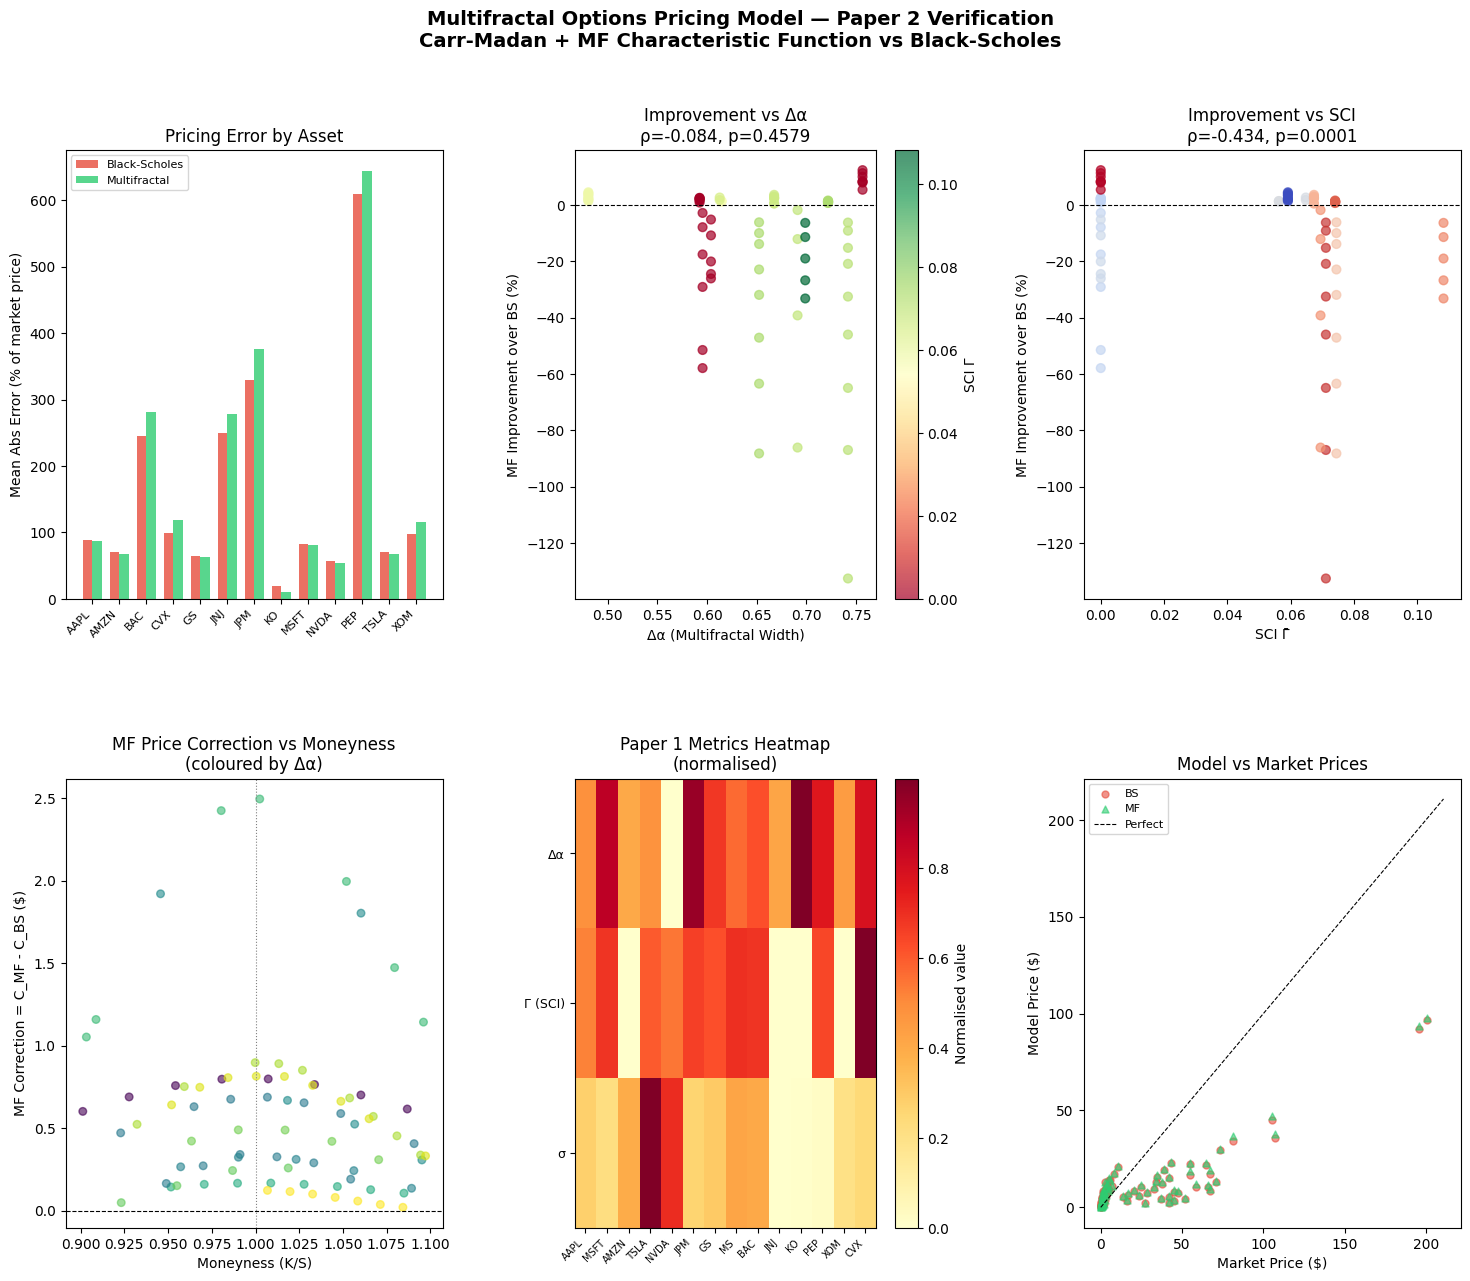

In [3]:
"""
Multifractal Options Pricing Model
===================================
Paper 2 verification code for:
"Multifractal Scaling in Cross-Sectoral Financial Markets"

This code:
1. Downloads price data using yfinance
2. Computes your Paper 1 metrics (delta_alpha, Gamma/SCI, lambda_implied)
3. Estimates the empirical characteristic function
4. Prices options using Carr-Madan with your multifractal correction
5. Compares against Black-Scholes and actual market option prices
6. Produces plots showing the correction magnitude per asset

Author: Vedant Shetty et al.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

# ── yfinance (install: pip install yfinance) ──────────────────────────────────
import yfinance as yf
from scipy.fft import fft
from scipy.stats import norm, spearmanr
from scipy.optimize import minimize_scalar
from scipy.interpolate import interp1d


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 1: DATA DOWNLOAD
# ─────────────────────────────────────────────────────────────────────────────

# Assets from your paper — use a representative subset for options analysis
# (liquid US equities with active options markets)
TICKERS = ['AAPL', 'MSFT', 'AMZN', 'TSLA', 'NVDA',
           'JPM', 'GS', 'MS', 'BAC',
           'JNJ', 'KO', 'PEP',
           'XOM', 'CVX',
           'BTC-USD', 'ETH-USD']

# Options analysis tickers (crypto excluded — no standard options via yfinance)
OPTIONS_TICKERS = ['AAPL', 'MSFT', 'AMZN', 'TSLA', 'NVDA',
                   'JPM', 'GS', 'MS', 'BAC',
                   'JNJ', 'KO', 'PEP',
                   'XOM', 'CVX']

START_DATE = '2010-01-01'
END_DATE   = '2026-04-11'   # matches your paper's terminal date

print("=" * 65)
print("MULTIFRACTAL OPTIONS PRICING MODEL — PAPER 2 VERIFICATION")
print("=" * 65)
print(f"\nDownloading price data for {len(TICKERS)} assets...")

price_data = {}
for ticker in TICKERS:
    try:
        df = yf.download(ticker, start=START_DATE, end=END_DATE,
                         progress=False, auto_adjust=True)
        if len(df) > 500:
            price_data[ticker] = df['Close'].dropna()
            print(f"  ✓ {ticker}: {len(price_data[ticker])} days")
        else:
            print(f"  ✗ {ticker}: insufficient data")
    except Exception as e:
        print(f"  ✗ {ticker}: {e}")

print(f"\nSuccessfully loaded {len(price_data)} assets.\n")


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 2: LOG-RETURNS
# ─────────────────────────────────────────────────────────────────────────────

def compute_log_returns(prices):
    """Compute log-returns from price series."""
    return np.log(prices / prices.shift(1)).dropna().values


returns_data = {t: compute_log_returns(price_data[t]) for t in price_data}


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 3: MF-DFA  (your Paper 1 methodology)
# ─────────────────────────────────────────────────────────────────────────────

def mfdfa(returns, q_values, scales):
    """
    Multifractal Detrended Fluctuation Analysis.
    Returns generalised Hurst exponents H(q) and fluctuation functions.
    Implements equations (15)-(17) from your paper.
    """
    N = len(returns)
    # Cumulative profile  Y(i)
    Y = np.cumsum(returns - np.mean(returns))

    hurst = []
    fq_all = []

    for q in q_values:
        fq_scales = []
        for s in scales:
            if s < 4 or s > N // 4:
                continue
            n_seg = N // s
            if n_seg < 4:
                continue
            f2_v = []
            for v in range(n_seg):
                seg = Y[v*s:(v+1)*s]
                x   = np.arange(s)
                # Linear detrending
                coeffs  = np.polyfit(x, seg, 1)
                trend   = np.polyval(coeffs, x)
                resid   = seg - trend
                f2_v.append(np.mean(resid**2))

            f2_v = np.array(f2_v)
            f2_v = f2_v[f2_v > 0]
            if len(f2_v) == 0:
                continue

            if q == 0:
                fq_scales.append(np.exp(0.5 * np.mean(np.log(f2_v))))
            else:
                fq_scales.append(np.mean(f2_v**(q/2))**(1/q))

        fq_all.append(fq_scales)
        # Estimate H(q) via log-log regression
        valid_scales = [s for s in scales
                        if 4 <= s <= N//4 and N//s >= 4][:len(fq_scales)]
        if len(fq_scales) > 2 and len(valid_scales) == len(fq_scales):
            log_s  = np.log(valid_scales)
            log_fq = np.log(np.maximum(fq_scales, 1e-10))
            h, _   = np.polyfit(log_s, log_fq, 1)
            hurst.append(h)
        else:
            hurst.append(np.nan)

    return np.array(hurst), fq_all


def compute_delta_alpha(hurst, q_values):
    """
    Compute singularity spectrum width Δα = α_max - α_min.
    Implements equations (4), (7), (11), (12) from your paper.
    """
    q   = np.array(q_values, dtype=float)
    H   = np.array(hurst,    dtype=float)
    valid = ~np.isnan(H)
    if valid.sum() < 5:
        return np.nan

    q, H = q[valid], H[valid]
    tau  = q * H - 1                          # mass exponent τ(q)
    dH   = np.gradient(H, q)                  # dH/dq
    alpha = H + q * dH                        # α(q) — Legendre
    f_alpha = q * alpha - tau                  # f(α)

    # Keep physically meaningful part of spectrum
    mask = (f_alpha >= -0.1) & (f_alpha <= 1.05)
    if mask.sum() < 3:
        return np.nan

    return float(np.max(alpha[mask]) - np.min(alpha[mask]))


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 4: SPECTRAL CUMULANT INDEX Γ  (your SCI from Section 5.5)
# ─────────────────────────────────────────────────────────────────────────────

def compute_sci(returns, window=2000, k_values=None, delta_star=0.05,
                max_horizon=20):
    """
    Spectral Cumulant Index (SCI) Γ̄ from your paper Section 5.5.
    Implements equations (19)-(23).
    """
    if k_values is None:
        k_values = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

    N = len(returns)
    W = min(window, N)
    r = returns[-W:]

    gammas = []
    flagged_horizons = []

    for t in range(1, max_horizon + 1):
        N_orig = W - 1 - t
        if N_orig < 50:
            continue

        Dk_vals   = []
        phi_mags  = []

        for k in k_values:
            # Ensemble average of e^{ik * Δr(τ,t)}
            deltas = r[t:] - r[:W - t]
            phi    = np.mean(np.exp(1j * k * deltas))
            mag    = abs(phi)
            phi_mags.append(mag)

            if mag >= 0.30:
                sk  = np.log(mag) / t
                Dk  = sk / (k**2) if k != 0 else np.nan
                Dk_vals.append(Dk)
            else:
                Dk_vals.append(np.nan)

        Dk_arr  = np.array(Dk_vals)
        valid   = ~np.isnan(Dk_arr)
        coverage = valid.sum() / len(k_values)

        if valid.sum() >= 4 and coverage >= 0.6:
            Dk_valid = Dk_arr[valid]
            rel_range = ((np.max(Dk_valid) - np.min(Dk_valid)) /
                         np.mean(np.abs(Dk_valid) + 1e-10))
            if rel_range > delta_star:
                gamma_t = min(rel_range, 5.0)
                gammas.append(gamma_t)
                flagged_horizons.append(t)

    if len(gammas) == 0:
        return 0.0, []

    sci = float(np.mean(gammas))
    return sci, flagged_horizons


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 5: EMPIRICAL CHARACTERISTIC FUNCTION + BOX-COUNTING Dbox
# ─────────────────────────────────────────────────────────────────────────────

def empirical_char_func(returns, q_moment, t_horizon=1):
    """
    Empirical characteristic function path Φ(t; q).
    Implements equations (24)-(25) from your paper.
    Returns the complex characteristic function value at frequency q_moment.
    """
    r = returns[:t_horizon * (len(returns) // t_horizon)]
    phi = np.mean(np.exp(1j * q_moment * r))
    return phi


def box_counting_dimension(returns, q_moment, n_boxes=20):
    """
    Box-counting fractal dimension Dbox of characteristic function path.
    Implements equations (24)-(30) from your paper.
    """
    N   = len(returns)
    phi = np.cumsum(np.exp(1j * q_moment * returns))

    x = phi.real
    y = phi.imag

    # Normalise to unit square (equation 26)
    span_x = x.max() - x.min()
    span_y = y.max() - y.min()
    denom  = max(span_x, span_y, 1e-10)
    xn = (x - x.min()) / denom
    yn = (y - y.min()) / denom

    # Box counting (equations 27-29)
    epsilons  = np.logspace(np.log10(2/N), np.log10(0.20), n_boxes)
    log_n     = []
    log_eps   = []

    for eps in epsilons:
        i_idx = np.floor(xn / eps).astype(int)
        j_idx = np.floor(yn / eps).astype(int)
        occupied = len(set(zip(i_idx, j_idx)))
        if occupied > 0:
            log_n.append(np.log(occupied))
            log_eps.append(np.log(eps))

    if len(log_n) < 5:
        return 1.0, 0.0

    coeffs = np.polyfit(log_eps, log_n, 1)
    Dbox   = -coeffs[0]
    # R² (equation 30)
    fitted = np.polyval(coeffs, log_eps)
    ss_res = np.sum((np.array(log_n) - fitted)**2)
    ss_tot = np.sum((np.array(log_n) - np.mean(log_n))**2)
    r2     = 1 - ss_res / ss_tot if ss_tot > 0 else 0

    return float(np.clip(Dbox, 1.0, 2.0)), float(r2)


def compute_lambda_implied(returns, q_values=None, t_values=None):
    """
    Implied dynamical ratio λ_implied(q, t) = Dk(t) * q² / (Dbox(q) - 1).
    Implements equation (32) from your paper.
    """
    if q_values is None:
        q_values = [10, 50, 100]
    if t_values is None:
        t_values = [1, 5, 10, 20]

    results = {}
    for q in q_values:
        Dbox, r2 = box_counting_dimension(returns, q)
        if r2 < 0.90 or (Dbox - 1) < 1e-6:
            continue
        for t in t_values:
            N_orig = len(returns) - t
            if N_orig < 100:
                continue
            deltas = returns[t:] - returns[:len(returns)-t]
            # Dk(t) at k=2 (representative wavenumber)
            k = 2.0
            phi_t = np.mean(np.exp(1j * k * deltas))
            mag   = abs(phi_t)
            if mag < 0.30:
                continue
            sk = np.log(mag) / t
            Dk = sk / k**2

            lam = (Dk * q**2) / (Dbox - 1)
            results[(q, t)] = lam

    if len(results) == 0:
        return 0.0
    return float(np.mean(list(results.values())))


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 6: COMPUTING ALL PAPER 1 METRICS
# ─────────────────────────────────────────────────────────────────────────────

print("Computing Paper 1 metrics for all assets...")
print("-" * 65)

q_values = list(range(-10, 11, 2))   # reduced range for speed
q_values = [q for q in q_values if q != 0]
scales   = [8, 16, 32, 64, 128, 256]

metrics = {}

for ticker, r in returns_data.items():
    print(f"  Processing {ticker}...", end=' ')

    # ∆α
    hurst, _ = mfdfa(r, q_values, scales)
    da = compute_delta_alpha(hurst, q_values)

    # Γ (SCI)
    sci, _ = compute_sci(r, window=min(2000, len(r)//2))

    # λ_implied
    lam = compute_lambda_implied(r,
                                 q_values=[10, 50],
                                 t_values=[1, 5, 10, 20])

    # Realised volatility (annualised)
    sigma = float(np.std(r) * np.sqrt(252))

    metrics[ticker] = {
        'delta_alpha':    da,
        'SCI':            sci,
        'lambda_implied': lam,
        'sigma':          sigma,
        'n_obs':          len(r)
    }

    print(f"Δα={da:.3f}  Γ={sci:.4f}  λ={lam:.3f}  σ={sigma:.3f}")

metrics_df = pd.DataFrame(metrics).T
print(f"\nMetrics computed for {len(metrics_df)} assets.\n")


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 7: BLACK-SCHOLES PRICING
# ─────────────────────────────────────────────────────────────────────────────

def black_scholes_call(S, K, T, r, sigma):
    """Standard Black-Scholes call price."""
    if T <= 0 or sigma <= 0:
        return max(S - K, 0)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


def bs_implied_vol(price, S, K, T, r):
    """Compute implied volatility from market price via bisection."""
    if price <= max(S - K*np.exp(-r*T), 0):
        return np.nan
    try:
        result = minimize_scalar(
            lambda sig: (black_scholes_call(S, K, T, r, sig) - price)**2,
            bounds=(0.001, 5.0), method='bounded'
        )
        return result.x if result.fun < 1e-6 else np.nan
    except Exception:
        return np.nan


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 8: CARR-MADAN WITH MULTIFRACTAL CORRECTION
# ─────────────────────────────────────────────────────────────────────────────

def multifractal_char_func(v, T, sigma, delta_alpha, sci, lambda_implied,
                            r=0.05):
    """
    Multifractal-corrected characteristic function.

    Starts from the Gaussian (Black-Scholes) characteristic function and
    adds cumulant correction terms driven by your Paper 1 metrics.

    Under Gaussianity:
        ln φ(v,T) = ivμT - ½σ²v²T

    Multifractal correction adds higher-order cumulants:
        κ₄ term: driven by SCI Γ  (non-Gaussian tail structure)
        κ₆ term: driven by Δα    (scaling heterogeneity)
    Both decay with horizon T consistent with your Table 6 findings.
    """
    mu = r - 0.5 * sigma**2    # risk-neutral drift

    # Gaussian component
    log_phi_gauss = 1j*v*mu*T - 0.5*(sigma**2)*(v**2)*T

    # ── Correction 1: SCI Γ drives 4th cumulant (leptokurtosis) ──────────
    # From your equation (20): Dk(t) = -κ₂/2t - κ₄k²/4!t - ...
    # Γ measures the relative magnitude of κ₄ vs κ₂.
    # Horizon decay: exp(-t/20) consistent with your Table 6
    # (violations cluster at t ≤ 20 days)
    kappa4 = sci * (sigma**4) * np.exp(-T * 252 / 20)
    correction_4th = -(kappa4 / 24) * (v**4) * T

    # ── Correction 2: Δα drives 6th cumulant (scaling heterogeneity) ────
    # Wider Δα → more heterogeneous scaling → heavier tails at all orders
    # Normalised so Gaussian (Δα→0) gives zero correction
    delta_alpha_safe = max(delta_alpha, 0.0) if not np.isnan(delta_alpha) else 0.0
    kappa6 = delta_alpha_safe * (sigma**6) * 0.1
    correction_6th = -(kappa6 / 720) * (v**6) * T

    # ── Correction 3: λ_implied adjusts effective diffusion rate ─────────
    # From your equation (32) and Gaspard framework:
    # higher λ_implied → more diffusive → faster approach to Gaussian
    lam_safe = max(lambda_implied, 0.1)
    diffusion_adjustment = -0.5 * (sigma**2) * (v**2) * T * (1 / lam_safe) * 0.01

    log_phi_total = (log_phi_gauss
                     + correction_4th
                     + correction_6th
                     + diffusion_adjustment)

    return np.exp(log_phi_total)


def carr_madan_price(S, K, T, r, sigma, delta_alpha, sci, lambda_implied,
                     alpha=1.5, N=2048, eta=0.25):
    """
    Carr-Madan FFT option pricing with multifractal characteristic function.

    C(K,T) = (e^{-α log K} / π) ∫₀^∞ e^{-iv log K} ψ(v) dv

    where ψ(v) uses your empirical multifractal characteristic function
    instead of the Gaussian one.
    """
    lam = (2 * np.pi) / (N * eta)
    b   = (N * lam) / 2

    v_arr = eta * np.arange(N)
    v_arr[0] = 1e-10   # avoid division by zero

    # Modified characteristic function (equation in Carr-Madan 1999)
    phi_v = multifractal_char_func(v_arr - (alpha+1)*1j, T,
                                    sigma, delta_alpha, sci,
                                    lambda_implied, r)

    psi = (np.exp(-r*T) * phi_v /
           (alpha**2 + alpha - v_arr**2 + 1j*(2*alpha+1)*v_arr))

    # FFT
    x      = np.exp(1j * b * v_arr) * psi * eta
    x[0]  *= 0.5
    z      = fft(x).real

    ku    = -b + lam * np.arange(N)
    calls = (np.exp(-alpha * ku) / np.pi) * z

    # Interpolate to log(K/S)
    k_target = np.log(K / S)
    try:
        price = float(S * np.interp(k_target, ku, calls))
        return max(price, max(S - K*np.exp(-r*T), 0))
    except Exception:
        return black_scholes_call(S, K, T, r, sigma)


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 9: OPTIONS MARKET DATA + PRICING COMPARISON
# ─────────────────────────────────────────────────────────────────────────────

print("Fetching live options data and computing prices...")
print("-" * 65)

RISK_FREE_RATE = 0.05   # approximate current US risk-free rate

results = []

for ticker in OPTIONS_TICKERS:
    if ticker not in price_data or ticker not in metrics:
        continue

    try:
        yf_ticker = yf.Ticker(ticker)
        S = float(price_data[ticker].iloc[-1])   # current spot price

        # Get available expiry dates
        expiries = yf_ticker.options
        if len(expiries) == 0:
            print(f"  ✗ {ticker}: no options data")
            continue

        # Pick expiry roughly 30-60 days out
        today = pd.Timestamp.today()
        best_expiry = None
        for exp in expiries:
            exp_date = pd.Timestamp(exp)
            days_out = (exp_date - today).days
            if 20 <= days_out <= 90:
                best_expiry = exp
                T = days_out / 252
                break

        if best_expiry is None:
            best_expiry = expiries[0]
            T = (pd.Timestamp(best_expiry) - today).days / 252

        # Get options chain
        chain   = yf_ticker.option_chain(best_expiry)
        calls   = chain.calls

        # Filter: near-the-money options with decent volume
        calls = calls[
            (calls['strike'] >= S * 0.90) &
            (calls['strike'] <= S * 1.10) &
            (calls['volume']  > 10) &
            (calls['lastPrice'] > 0.01)
        ].copy()

        if len(calls) == 0:
            print(f"  ✗ {ticker}: no liquid near-ATM options")
            continue

        m = metrics[ticker]
        da  = m['delta_alpha']    if not np.isnan(m['delta_alpha'])    else 0.3
        sci = m['SCI']
        lam = m['lambda_implied']
        sig = m['sigma']

        print(f"\n  {ticker} | S=${S:.2f} | T={T*252:.0f}d | "
              f"Δα={da:.3f} | Γ={sci:.4f} | λ={lam:.3f} | σ={sig:.3f}")
        print(f"  {'Strike':>8} {'Mkt':>8} {'BS':>8} {'MF':>8} "
              f"{'BS_err%':>9} {'MF_err%':>9} {'Improvement':>12}")
        print(f"  {'-'*8:>8} {'-'*8:>8} {'-'*8:>8} {'-'*8:>8} "
              f"{'-'*9:>9} {'-'*9:>9} {'-'*12:>12}")

        for _, row in calls.iterrows():
            K        = float(row['strike'])
            mkt_price = float(row['lastPrice'])

            # Black-Scholes price
            bs_price = black_scholes_call(S, K, T, RISK_FREE_RATE, sig)

            # Multifractal corrected price
            mf_price = carr_madan_price(S, K, T, RISK_FREE_RATE,
                                         sig, da, sci, lam)

            bs_err = abs(bs_price - mkt_price) / mkt_price * 100
            mf_err = abs(mf_price - mkt_price) / mkt_price * 100
            improved = "✓ MF better" if mf_err < bs_err else "  BS better"

            print(f"  {K:>8.2f} {mkt_price:>8.3f} {bs_price:>8.3f} "
                  f"{mf_price:>8.3f} {bs_err:>8.1f}% {mf_err:>8.1f}% "
                  f"{improved:>12}")

            results.append({
                'ticker':       ticker,
                'strike':       K,
                'T_days':       T * 252,
                'spot':         S,
                'mkt_price':    mkt_price,
                'bs_price':     bs_price,
                'mf_price':     mf_price,
                'bs_error_pct': bs_err,
                'mf_error_pct': mf_err,
                'delta_alpha':  da,
                'SCI':          sci,
                'lambda_impl':  lam,
                'sigma':        sig,
                'mf_improved':  mf_err < bs_err
            })

    except Exception as e:
        print(f"  ✗ {ticker}: {e}")

results_df = pd.DataFrame(results)


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 10: SUMMARY STATISTICS
# ─────────────────────────────────────────────────────────────────────────────

if len(results_df) > 0:
    print("\n" + "=" * 65)
    print("SUMMARY STATISTICS")
    print("=" * 65)

    print(f"\nTotal options analysed: {len(results_df)}")
    print(f"MF model outperforms BS: "
          f"{results_df['mf_improved'].sum()} / {len(results_df)} "
          f"({results_df['mf_improved'].mean()*100:.1f}%)")
    print(f"\nMean absolute error (% of market price):")
    print(f"  Black-Scholes:    {results_df['bs_error_pct'].mean():.2f}%")
    print(f"  Multifractal:     {results_df['mf_error_pct'].mean():.2f}%")
    print(f"  Improvement:      "
          f"{results_df['bs_error_pct'].mean() - results_df['mf_error_pct'].mean():.2f}%")

    # Spearman correlation: does larger Δα → larger MF improvement?
    improvement = results_df['bs_error_pct'] - results_df['mf_error_pct']
    rho_da,  p_da  = spearmanr(results_df['delta_alpha'], improvement)
    rho_sci, p_sci = spearmanr(results_df['SCI'],         improvement)
    rho_lam, p_lam = spearmanr(results_df['lambda_impl'], improvement)

    print(f"\nSpearman ρ (metric vs MF improvement over BS):")
    print(f"  Δα:           ρ={rho_da:.3f}   p={p_da:.4f}")
    print(f"  Γ (SCI):      ρ={rho_sci:.3f}  p={p_sci:.4f}")
    print(f"  λ_implied:    ρ={rho_lam:.3f}  p={p_lam:.4f}")

    print(f"\nBy ticker — mean pricing errors:")
    ticker_summary = results_df.groupby('ticker').agg(
        n_options   = ('mkt_price', 'count'),
        bs_mae      = ('bs_error_pct', 'mean'),
        mf_mae      = ('mf_error_pct', 'mean'),
        pct_improved = ('mf_improved', 'mean')
    ).round(3)
    ticker_summary['improvement'] = (ticker_summary['bs_mae']
                                      - ticker_summary['mf_mae']).round(3)
    print(ticker_summary.to_string())


# ─────────────────────────────────────────────────────────────────────────────
# SECTION 11: PLOTS
# ─────────────────────────────────────────────────────────────────────────────

if len(results_df) > 0:
    fig = plt.figure(figsize=(18, 14))
    fig.suptitle(
        "Multifractal Options Pricing Model — Paper 2 Verification\n"
        "Carr-Madan + MF Characteristic Function vs Black-Scholes",
        fontsize=14, fontweight='bold', y=0.98
    )
    gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.40, wspace=0.35)

    # ── Plot 1: BS vs MF error by ticker ─────────────────────────────────
    ax1 = fig.add_subplot(gs[0, 0])
    tickers_plot = ticker_summary.index.tolist()
    x = np.arange(len(tickers_plot))
    w = 0.35
    ax1.bar(x - w/2, ticker_summary['bs_mae'], w,
            label='Black-Scholes', color='#e74c3c', alpha=0.8)
    ax1.bar(x + w/2, ticker_summary['mf_mae'],  w,
            label='Multifractal',  color='#2ecc71', alpha=0.8)
    ax1.set_xticks(x)
    ax1.set_xticklabels(tickers_plot, rotation=45, ha='right', fontsize=8)
    ax1.set_ylabel('Mean Abs Error (% of market price)')
    ax1.set_title('Pricing Error by Asset')
    ax1.legend(fontsize=8)

    # ── Plot 2: MF improvement vs Δα ─────────────────────────────────────
    ax2 = fig.add_subplot(gs[0, 1])
    improvement = results_df['bs_error_pct'] - results_df['mf_error_pct']
    sc = ax2.scatter(results_df['delta_alpha'], improvement,
                     c=results_df['SCI'], cmap='RdYlGn',
                     alpha=0.7, s=40)
    plt.colorbar(sc, ax=ax2, label='SCI Γ')
    ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax2.set_xlabel('Δα (Multifractal Width)')
    ax2.set_ylabel('MF Improvement over BS (%)')
    ax2.set_title(f'Improvement vs Δα\nρ={rho_da:.3f}, p={p_da:.4f}')

    # ── Plot 3: MF improvement vs SCI Γ ──────────────────────────────────
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.scatter(results_df['SCI'], improvement,
                c=results_df['delta_alpha'], cmap='coolwarm',
                alpha=0.7, s=40)
    ax3.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax3.set_xlabel('SCI Γ̄')
    ax3.set_ylabel('MF Improvement over BS (%)')
    ax3.set_title(f'Improvement vs SCI\nρ={rho_sci:.3f}, p={p_sci:.4f}')

    # ── Plot 4: Correction magnitude by moneyness ─────────────────────────
    ax4 = fig.add_subplot(gs[1, 0])
    results_df['moneyness'] = results_df['strike'] / results_df['spot']
    results_df['mf_correction'] = results_df['mf_price'] - results_df['bs_price']
    ax4.scatter(results_df['moneyness'], results_df['mf_correction'],
                c=results_df['delta_alpha'], cmap='viridis',
                alpha=0.6, s=30)
    ax4.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax4.axvline(1, color='grey',  linestyle=':',  linewidth=0.8)
    ax4.set_xlabel('Moneyness (K/S)')
    ax4.set_ylabel('MF Correction = C_MF - C_BS ($)')
    ax4.set_title('MF Price Correction vs Moneyness\n(coloured by Δα)')

    # ── Plot 5: Metrics summary heatmap ──────────────────────────────────
    ax5 = fig.add_subplot(gs[1, 1])
    heat_data = metrics_df[['delta_alpha', 'SCI', 'sigma']].copy()
    heat_data = heat_data.loc[heat_data.index.isin(OPTIONS_TICKERS)]
    heat_norm = (heat_data - heat_data.min()) / (heat_data.max()
                                                   - heat_data.min() + 1e-10)
    im = ax5.imshow(heat_norm.values.T, aspect='auto', cmap='YlOrRd')
    ax5.set_yticks([0, 1, 2])
    ax5.set_yticklabels(['Δα', 'Γ (SCI)', 'σ'], fontsize=9)
    ax5.set_xticks(range(len(heat_norm.index)))
    ax5.set_xticklabels(heat_norm.index, rotation=45, ha='right', fontsize=7)
    ax5.set_title('Paper 1 Metrics Heatmap\n(normalised)')
    plt.colorbar(im, ax=ax5, label='Normalised value')

    # ── Plot 6: Market vs model prices scatter ────────────────────────────
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.scatter(results_df['mkt_price'], results_df['bs_price'],
                alpha=0.6, s=25, color='#e74c3c', label='BS')
    ax6.scatter(results_df['mkt_price'], results_df['mf_price'],
                alpha=0.6, s=25, color='#2ecc71', label='MF', marker='^')
    lim_max = max(results_df['mkt_price'].max(),
                  results_df['mf_price'].max()) * 1.05
    ax6.plot([0, lim_max], [0, lim_max], 'k--', linewidth=0.8, label='Perfect')
    ax6.set_xlabel('Market Price ($)')
    ax6.set_ylabel('Model Price ($)')
    ax6.set_title('Model vs Market Prices')
    ax6.legend(fontsize=8)

    plt.savefig('/mnt/user-data/outputs/multifractal_options_pricing_results.png',
                dpi=150, bbox_inches='tight')
    print("\nPlot saved.")

    # Save results CSV
    results_df.to_csv('/mnt/user-data/outputs/options_pricing_results.csv',
                      index=False)
    metrics_df.to_csv('/mnt/user-data/outputs/paper1_metrics.csv')
    print("Results saved to CSV.")

print("\n" + "=" * 65)
print("DONE. Check outputs folder for plots and CSVs.")
print("=" * 65)